In [3]:
# BLOC 1 — Charger, nettoyer, agréger par catégorie
import pandas as pd

# Lire le fichier (en-tête des colonnes sur la 3e ligne = index 2)
df = pd.read_excel("../data/Value per month per Chain - Product.xlsx", header=2)
# Enlever les lignes vides (bas de tableau, totaux)
df = df.dropna(subset=["Chain - Product"])

# Convertir la date texte en vraie date
df["date"] = pd.to_datetime(df["reference_date"])

# Agréger par catégorie et par mois (la somme règle aussi les doublons de SKU)
cat = (df.groupby(["product_line", "date"])["value"].sum()
         .reset_index()
         .rename(columns={"product_line": "categorie", "value": "ventes"}))

# Vérifications
print("Nombre de lignes après agrégation :", len(cat))
print("\nNombre de mois par catégorie :")
print(cat.groupby("categorie")["date"].nunique())
print("\nAperçu Dog :")
print(cat[cat["categorie"] == "Dog"].head(6).to_string(index=False))

Nombre de lignes après agrégation : 190

Nombre de mois par catégorie :
categorie
Cat           43
Cat Treats    18
Dental        43
Dog           43
Dog Treats    43
Name: date, dtype: int64

Aperçu Dog :
categorie       date    ventes
      Dog 2023-01-31  56504.03
      Dog 2023-02-28  53432.85
      Dog 2023-03-31 101062.96
      Dog 2023-04-30  74147.96
      Dog 2023-05-31  86241.36
      Dog 2023-06-30  85828.71


Train : 31 mois (de 2023-01-31 à 2025-07-31)
Test  : 12 mois  (de 2025-08-31 à 2026-07-31)

>>> MAPE de la baseline saisonnière sur Dog : 25.8%


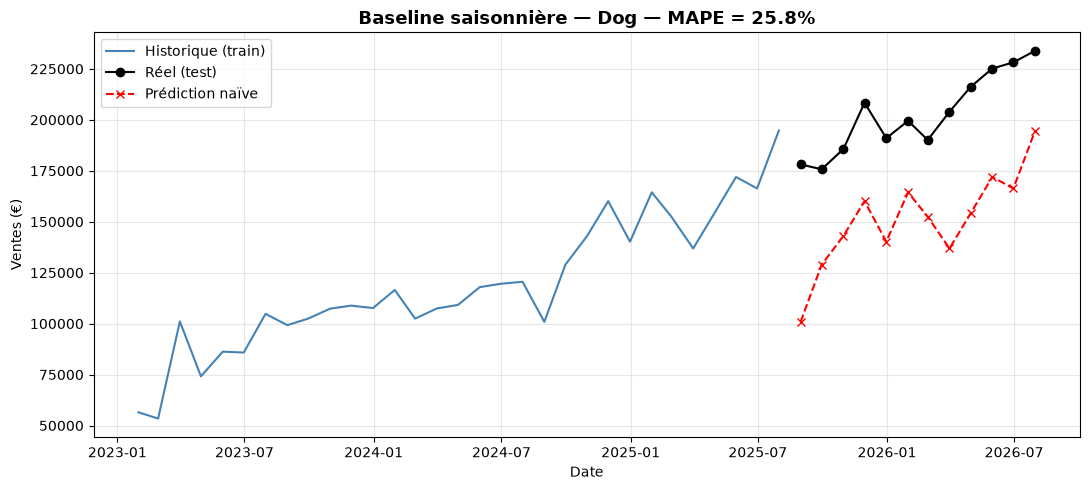

In [5]:
# BLOC 2 — Baseline saisonnière naïve sur Dog
import numpy as np
import matplotlib.pyplot as plt

# 1) Isoler la série Dog, triée par date
dog = cat[cat["categorie"] == "Dog"].sort_values("date").reset_index(drop=True)

# 2) Découper train / test : les 12 derniers mois en test
n_test = 12
train = dog.iloc[:-n_test].copy()
test  = dog.iloc[-n_test:].copy()

print(f"Train : {len(train)} mois (de {train['date'].min().date()} à {train['date'].max().date()})")
print(f"Test  : {len(test)} mois  (de {test['date'].min().date()} à {test['date'].max().date()})")

# 3) Prédiction naïve : chaque valeur de test = valeur du même mois, 12 mois plus tôt
predictions = []
for date_test in test["date"]:
    date_precedente = date_test - pd.DateOffset(years=1)
    valeur = dog.loc[dog["date"] == date_precedente, "ventes"].values[0]
    predictions.append(valeur)

test["prediction"] = predictions

# 4) Calcul du MAPE (Mean Absolute Percentage Error)
test["erreur_pct"] = np.abs(test["ventes"] - test["prediction"]) / test["ventes"] * 100
mape = test["erreur_pct"].mean()

print(f"\n>>> MAPE de la baseline saisonnière sur Dog : {mape:.1f}%")

# 5) Graphique
plt.figure(figsize=(11, 5))
plt.plot(train["date"], train["ventes"], label="Historique (train)", color="steelblue")
plt.plot(test["date"],  test["ventes"], label="Réel (test)", color="black", marker="o")
plt.plot(test["date"],  test["prediction"], label="Prédiction naïve", color="red", marker="x", linestyle="--")
plt.title(f"Baseline saisonnière — Dog — MAPE = {mape:.1f}%", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/baseline_dog.png", dpi=110, bbox_inches="tight")
plt.show()

c:\Users\G096103\OneDrive - General Mills\Desktop\Eugenia\memoire_forecast_edgardcooper\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.
20:11:19 - cmdstanpy - INFO - Chain [1] start processing
20:11:20 - cmdstanpy - INFO - Chain [1] done processing


>>> MAPE Prophet sur Dog : 5.0%
>>> MAPE Baseline (rappel) : 25.8%
>>> Gain vs baseline : +20.8 points de MAPE


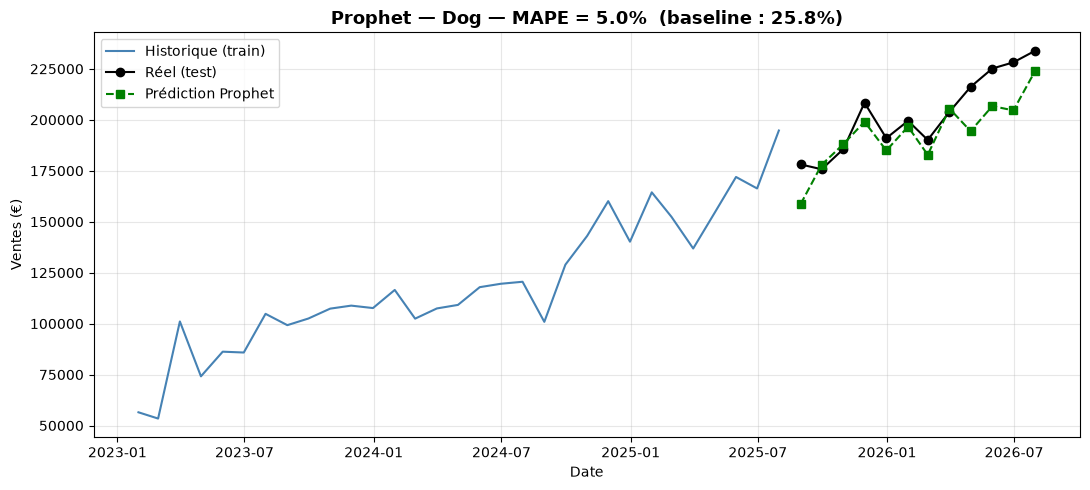

In [6]:
# BLOC 3 — Prophet sur Dog
from prophet import Prophet

# 1) Prophet exige exactement 2 colonnes nommées "ds" (date) et "y" (valeur).
#    On prépare la série complète Dog dans ce format.
dog_prophet = dog[["date", "ventes"]].rename(columns={"date": "ds", "ventes": "y"})

# 2) Même découpage train/test que pour la baseline (12 derniers mois en test)
n_test = 12
train_p = dog_prophet.iloc[:-n_test].copy()
test_p  = dog_prophet.iloc[-n_test:].copy()

# 3) Créer le modèle et l'entraîner uniquement sur le train
#    - yearly_seasonality=True : on demande explicitement la saisonnalité annuelle
#    - weekly/daily désactivées : on est en mensuel, ça n'a pas de sens
modele = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
modele.fit(train_p)

# 4) Créer les 12 dates futures à prédire (correspondent au test)
futur = modele.make_future_dataframe(periods=n_test, freq="ME")   # ME = month end
prevision = modele.predict(futur)

# 5) Récupérer uniquement les 12 dernières prédictions (celles qui correspondent au test)
pred_test = prevision[["ds", "yhat"]].iloc[-n_test:].reset_index(drop=True)

# 6) Calcul du MAPE — même méthode que pour la baseline, pour pouvoir comparer
comparaison = test_p.reset_index(drop=True).copy()
comparaison["prediction"] = pred_test["yhat"].values
comparaison["erreur_pct"] = np.abs(comparaison["y"] - comparaison["prediction"]) / comparaison["y"] * 100
mape_prophet = comparaison["erreur_pct"].mean()

print(f">>> MAPE Prophet sur Dog : {mape_prophet:.1f}%")
print(f">>> MAPE Baseline (rappel) : {mape:.1f}%")
gain = mape - mape_prophet
print(f">>> Gain vs baseline : {gain:+.1f} points de MAPE")

# 7) Graphique comparatif
plt.figure(figsize=(11, 5))
plt.plot(train_p["ds"], train_p["y"], label="Historique (train)", color="steelblue")
plt.plot(test_p["ds"],  test_p["y"], label="Réel (test)", color="black", marker="o")
plt.plot(comparaison["ds"], comparaison["prediction"], label="Prédiction Prophet", color="green", marker="s", linestyle="--")
plt.title(f"Prophet — Dog — MAPE = {mape_prophet:.1f}%  (baseline : {mape:.1f}%)", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/prophet_dog.png", dpi=110, bbox_inches="tight")
plt.show()

Recherche des meilleurs paramètres SARIMA (peut prendre 20-40 secondes)...
Modèle retenu : (1, 0, 2) x (0, 1, 1, 12)

BENCHMARK SUR DOG
Baseline naïve : 25.8%
SARIMA         : 3.2%
Prophet        : 5.0%


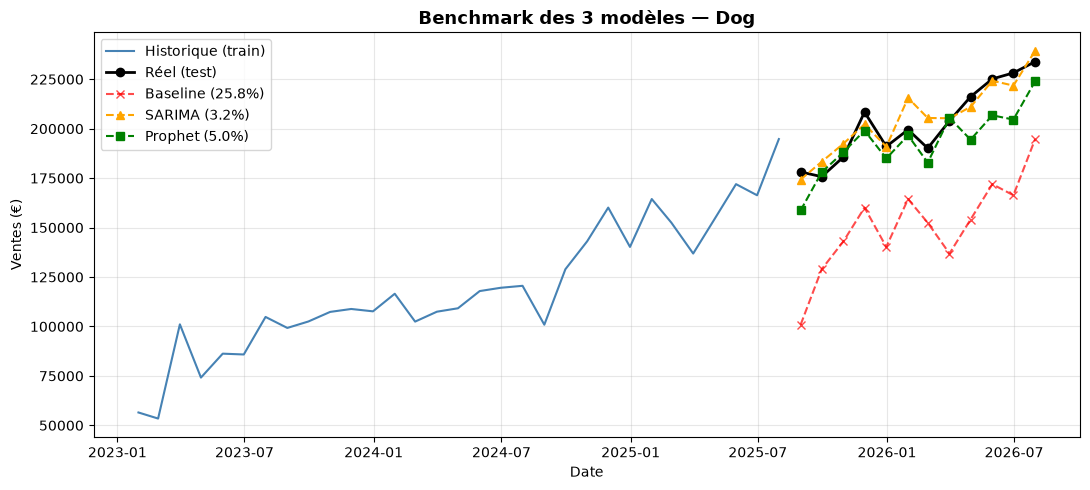

In [8]:
# BLOC 4 — SARIMA sur Dog (via auto_arima)
from pmdarima import auto_arima

# 1) Même découpage train/test qu'avant, pour être comparable
n_test = 12
serie = dog.sort_values("date").reset_index(drop=True)
train_s = serie.iloc[:-n_test]
test_s  = serie.iloc[-n_test:]

# 2) auto_arima cherche automatiquement les meilleurs paramètres SARIMA
#    m=12 : période saisonnière annuelle (12 mois)
#    seasonal=True : on active la composante saisonnière
#    stepwise=True : recherche rapide (au lieu de tester TOUTES les combinaisons)
print("Recherche des meilleurs paramètres SARIMA (peut prendre 20-40 secondes)...")
modele_sarima = auto_arima(
    train_s["ventes"],
    seasonal=True,
    m=12,
    stepwise=True,
    suppress_warnings=True,
    trace=False,
)

print(f"Modèle retenu : {modele_sarima.order} x {modele_sarima.seasonal_order}")

# 3) Prévision sur les 12 mois de test
pred_sarima = modele_sarima.predict(n_periods=n_test)

# 4) Calcul du MAPE
comparaison_s = test_s.reset_index(drop=True).copy()
comparaison_s["prediction"] = pred_sarima.values
comparaison_s["erreur_pct"] = np.abs(comparaison_s["ventes"] - comparaison_s["prediction"]) / comparaison_s["ventes"] * 100
mape_sarima = comparaison_s["erreur_pct"].mean()

# 5) Récap comparatif des 3 modèles
print("\n" + "="*50)
print("BENCHMARK SUR DOG")
print("="*50)
print(f"Baseline naïve : {mape:.1f}%")
print(f"SARIMA         : {mape_sarima:.1f}%")
print(f"Prophet        : {mape_prophet:.1f}%")
print("="*50)

# 6) Graphique comparatif des 3 modèles
plt.figure(figsize=(11, 5))
plt.plot(train_s["date"], train_s["ventes"], label="Historique (train)", color="steelblue")
plt.plot(test_s["date"],  test_s["ventes"], label="Réel (test)", color="black", marker="o", linewidth=2)
plt.plot(test["date"],    test["prediction"], label=f"Baseline ({mape:.1f}%)", color="red", marker="x", linestyle="--", alpha=0.7)
plt.plot(comparaison_s["date"], comparaison_s["prediction"], label=f"SARIMA ({mape_sarima:.1f}%)", color="orange", marker="^", linestyle="--")
plt.plot(comparaison["ds"], comparaison["prediction"], label=f"Prophet ({mape_prophet:.1f}%)", color="green", marker="s", linestyle="--")
plt.title("Benchmark des 3 modèles — Dog", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/benchmark_dog.png", dpi=110, bbox_inches="tight")
plt.show()

→ Traitement de Dog...
→ Traitement de Cat...
→ Traitement de Dental...
→ Traitement de Dog Treats...

BENCHMARK GLOBAL — MAPE en %
 Catégorie  Baseline  SARIMA  Prophet
       Dog      25.8     3.2      5.0
       Cat      19.2     6.2     12.9
    Dental      16.0    15.1      9.2
Dog Treats      65.0    61.3     54.3


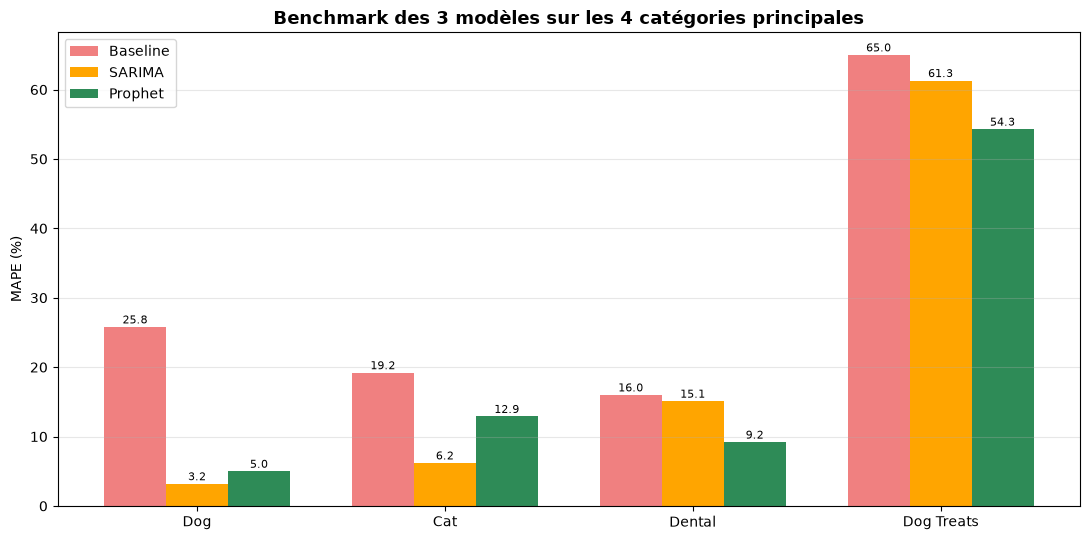


Tableau sauvegardé dans figures/benchmark_resultats.csv


In [9]:
# BLOC 5 — Industrialisation : 3 modèles × 4 catégories
import warnings
import logging

# Réduire au silence les messages verbeux de Prophet et pmdarima
warnings.filterwarnings("ignore")
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

# 1) Fonction générique qui calcule les 3 MAPE pour une catégorie donnée
def evaluer_categorie(nom_categorie, cat_df, n_test=12):
    # Isoler la série
    serie = cat_df[cat_df["categorie"] == nom_categorie].sort_values("date").reset_index(drop=True)
    train, test = serie.iloc[:-n_test].copy(), serie.iloc[-n_test:].copy()

    # --- Baseline saisonnière naïve ---
    pred_base = [serie.loc[serie["date"] == d - pd.DateOffset(years=1), "ventes"].values[0]
                 for d in test["date"]]
    mape_base = np.mean(np.abs(test["ventes"].values - np.array(pred_base)) / test["ventes"].values) * 100

    # --- Prophet ---
    df_p = serie[["date", "ventes"]].rename(columns={"date": "ds", "ventes": "y"})
    train_p = df_p.iloc[:-n_test]
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(train_p)
    futur = m.make_future_dataframe(periods=n_test, freq="ME")
    pred_prophet = m.predict(futur)["yhat"].iloc[-n_test:].values
    mape_prophet = np.mean(np.abs(test["ventes"].values - pred_prophet) / test["ventes"].values) * 100

    # --- SARIMA ---
    modele_s = auto_arima(train["ventes"], seasonal=True, m=12,
                          stepwise=True, suppress_warnings=True, trace=False)
    pred_sarima = modele_s.predict(n_periods=n_test).values
    mape_sarima = np.mean(np.abs(test["ventes"].values - pred_sarima) / test["ventes"].values) * 100

    return {
        "Catégorie": nom_categorie,
        "Baseline": round(mape_base, 1),
        "SARIMA": round(mape_sarima, 1),
        "Prophet": round(mape_prophet, 1),
    }

# 2) Boucle sur les 4 catégories retenues (Cat Treats exclue : 18 mois seulement)
categories_retenues = ["Dog", "Cat", "Dental", "Dog Treats"]
resultats = []
for c in categories_retenues:
    print(f"→ Traitement de {c}...")
    resultats.append(evaluer_categorie(c, cat))

# 3) Tableau de synthèse
resultats_df = pd.DataFrame(resultats)
print("\n" + "="*60)
print("BENCHMARK GLOBAL — MAPE en %")
print("="*60)
print(resultats_df.to_string(index=False))
print("="*60)

# 4) Graphique de synthèse (bar chart comparatif)
import numpy as np
x = np.arange(len(categories_retenues))
largeur = 0.25

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x - largeur, resultats_df["Baseline"], largeur, label="Baseline", color="lightcoral")
ax.bar(x,           resultats_df["SARIMA"],   largeur, label="SARIMA",   color="orange")
ax.bar(x + largeur, resultats_df["Prophet"],  largeur, label="Prophet",  color="seagreen")

ax.set_xticks(x)
ax.set_xticklabels(categories_retenues)
ax.set_ylabel("MAPE (%)")
ax.set_title("Benchmark des 3 modèles sur les 4 catégories principales", fontsize=13, fontweight="bold")
ax.legend()
ax.grid(alpha=0.3, axis="y")

# Annoter chaque barre avec la valeur
for i, cat_name in enumerate(categories_retenues):
    for j, (col, offset) in enumerate([("Baseline", -largeur), ("SARIMA", 0), ("Prophet", largeur)]):
        val = resultats_df.iloc[i][col]
        ax.text(i + offset, val + 0.5, f"{val:.1f}", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("../figures/benchmark_global.png", dpi=110, bbox_inches="tight")
plt.show()

# 5) Sauvegarde du tableau en CSV pour le mémoire
resultats_df.to_csv("../figures/benchmark_resultats.csv", index=False)
print("\nTableau sauvegardé dans figures/benchmark_resultats.csv")


PRÉVISIONS FUTURES — Dog
    Mois Prévision Min (IC 80%) Max (IC 80%)
Aug 2026 224 919 €    214 850 €    234 341 €
Sep 2026 231 705 €    222 639 €    241 508 €
Oct 2026 241 313 €    231 563 €    251 329 €
Nov 2026 252 892 €    243 820 €    262 668 €
Dec 2026 246 034 €    236 286 €    255 405 €
Jan 2027 251 052 €    241 647 €    261 590 €
Feb 2027 235 736 €    225 972 €    244 234 €
Mar 2027 270 433 €    260 937 €    279 257 €
Apr 2027 255 880 €    246 979 €    265 865 €
May 2027 266 134 €    256 738 €    275 527 €
Jun 2027 265 254 €    255 453 €    274 468 €
Jul 2027 284 158 €    275 120 €    294 016 €

PRÉVISIONS FUTURES — Cat
    Mois Prévision Min (IC 80%) Max (IC 80%)
Aug 2026 111 839 €    103 493 €    120 755 €
Sep 2026 113 711 €    105 567 €    122 608 €
Oct 2026 126 281 €    117 019 €    135 187 €
Nov 2026 135 054 €    126 430 €    144 111 €
Dec 2026 125 490 €    116 492 €    133 937 €
Jan 2027 124 270 €    115 981 €    133 255 €
Feb 2027 113 369 €    104 719 €    122 160 €
Mar

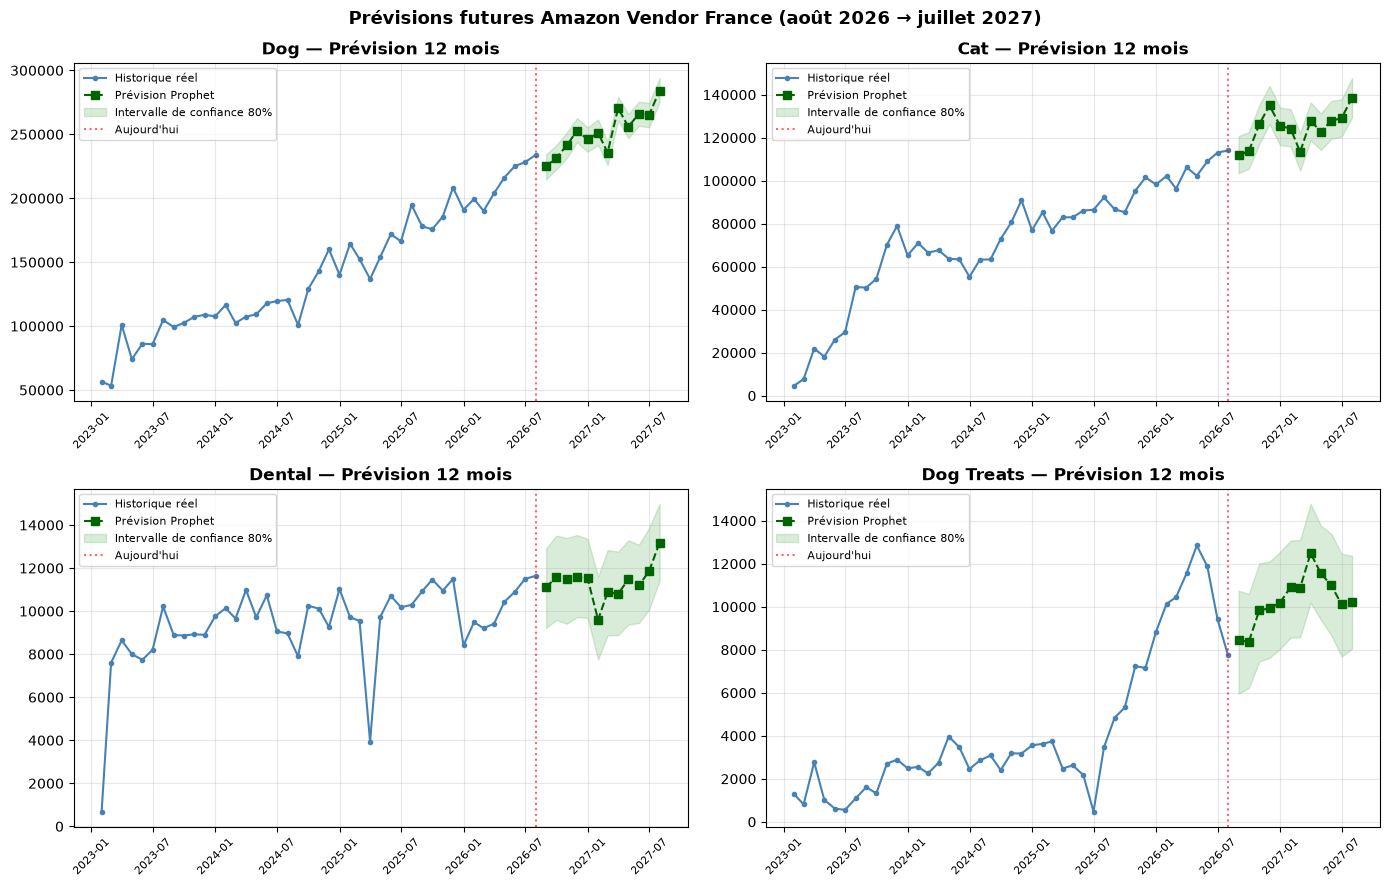


Tableau consolidé sauvegardé dans figures/previsions_futures.csv


In [10]:
# BLOC 6 — Prévisions FUTURES sur les 4 catégories (12 mois à venir)
# Cette fois on entraîne sur TOUTES les données pour prédire l'avenir réel.

horizon = 12  # nombre de mois à prédire dans le futur

previsions_futures = {}

for nom_cat in ["Dog", "Cat", "Dental", "Dog Treats"]:
    # 1) Prendre TOUTE la série (pas de découpage cette fois)
    serie = cat[cat["categorie"] == nom_cat].sort_values("date").reset_index(drop=True)
    df_p = serie[["date", "ventes"]].rename(columns={"date": "ds", "ventes": "y"})

    # 2) Entraîner Prophet sur l'historique complet
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False,
                interval_width=0.80)  # intervalle de confiance à 80%
    m.fit(df_p)

    # 3) Créer les 12 mois futurs et prédire
    futur = m.make_future_dataframe(periods=horizon, freq="ME")
    prev = m.predict(futur)

    # 4) On garde uniquement les 12 mois de prévision future
    prev_future = prev[["ds", "yhat", "yhat_lower", "yhat_upper"]].iloc[-horizon:].reset_index(drop=True)
    prev_future.columns = ["Mois", "Prévision", "Min (IC 80%)", "Max (IC 80%)"]
    previsions_futures[nom_cat] = prev_future

    # 5) Affichage lisible
    print(f"\n{'='*70}")
    print(f"PRÉVISIONS FUTURES — {nom_cat}")
    print(f"{'='*70}")
    affichage = prev_future.copy()
    affichage["Mois"] = affichage["Mois"].dt.strftime("%b %Y")
    for col in ["Prévision", "Min (IC 80%)", "Max (IC 80%)"]:
        affichage[col] = affichage[col].round(0).astype(int).apply(lambda x: f"{x:,} €".replace(",", " "))
    print(affichage.to_string(index=False))

# 6) Graphique de synthèse : historique + prévisions futures pour les 4 catégories
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, nom_cat in enumerate(["Dog", "Cat", "Dental", "Dog Treats"]):
    serie = cat[cat["categorie"] == nom_cat].sort_values("date")
    prev_future = previsions_futures[nom_cat]

    axes[i].plot(serie["date"], serie["ventes"], label="Historique réel", color="steelblue", marker="o", markersize=3)
    axes[i].plot(prev_future["Mois"], prev_future["Prévision"], label="Prévision Prophet", color="darkgreen", marker="s", linestyle="--")
    axes[i].fill_between(prev_future["Mois"], prev_future["Min (IC 80%)"], prev_future["Max (IC 80%)"],
                         color="green", alpha=0.15, label="Intervalle de confiance 80%")
    axes[i].axvline(serie["date"].max(), color="red", linestyle=":", alpha=0.6, label="Aujourd'hui")
    axes[i].set_title(f"{nom_cat} — Prévision {horizon} mois", fontweight="bold")
    axes[i].tick_params(axis="x", rotation=45, labelsize=8)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=8, loc="upper left")

fig.suptitle("Prévisions futures Amazon Vendor France (août 2026 → juillet 2027)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.savefig("../figures/previsions_futures.png", dpi=110, bbox_inches="tight")
plt.show()

# 7) Export CSV consolidé pour ton mémoire / manager
export = pd.concat([df.assign(Catégorie=c) for c, df in previsions_futures.items()], ignore_index=True)
export.to_csv("../figures/previsions_futures.csv", index=False)
print("\nTableau consolidé sauvegardé dans figures/previsions_futures.csv")

In [ ]:
# BLOC 7 — Backtest glissant sur Prophet (Dog & Cat)
# Objectif : vérifier que le MAPE tient sur plusieurs fenêtres de test

def backtest_glissant(nom_categorie, cat_df, n_test=12, n_folds=5, pas=3):
    """
    Entraîne Prophet sur plusieurs fenêtres successives et retourne le MAPE de chacune.
    - n_test : taille de la fenêtre de test (12 mois)
    - n_folds : nombre de fenêtres différentes à tester
    - pas : de combien de mois on décale la fenêtre entre 2 folds (3 = décalage trimestriel)
    """
    serie = cat_df[cat_df["categorie"] == nom_categorie].sort_values("date").reset_index(drop=True)
    df_p = serie[["date", "ventes"]].rename(columns={"date": "ds", "ventes": "y"})

    resultats = []
    total = len(df_p)

    for fold in range(n_folds):
        # Coupure : la fenêtre de test glisse dans le passé de "pas" mois à chaque fold
        end_test = total - fold * pas
        start_test = end_test - n_test
        if start_test < 12:  # sécurité : on ne teste pas si l'entraînement est trop court
            break

        train_fold = df_p.iloc[:start_test]
        test_fold  = df_p.iloc[start_test:end_test]

        # Entraînement et prédiction
        m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m.fit(train_fold)
        futur = m.make_future_dataframe(periods=n_test, freq="ME")
        pred = m.predict(futur)["yhat"].iloc[-n_test:].values

        # MAPE de cette fenêtre
        mape_fold = np.mean(np.abs(test_fold["y"].values - pred) / test_fold["y"].values) * 100
        resultats.append({
            "Fold": fold + 1,
            "Période test": f"{test_fold['ds'].min().strftime('%b %Y')} → {test_fold['ds'].max().strftime('%b %Y')}",
            "Taille train": len(train_fold),
            "MAPE (%)": round(mape_fold, 1),
        })

    return pd.DataFrame(resultats)

# Exécution sur Dog et Cat
for nom_cat in ["Dog", "Cat"]:
    print(f"\n{'='*70}")
    print(f"BACKTEST GLISSANT — {nom_cat} (Prophet)")
    print(f"{'='*70}")
    df_backtest = backtest_glissant(nom_cat, cat, n_test=12, n_folds=5, pas=3)
    print(df_backtest.to_string(index=False))
    print(f"\n>>> MAPE moyen sur les {len(df_backtest)} folds : {df_backtest['MAPE (%)'].mean():.1f}%")
    print(f">>> Écart-type : ±{df_backtest['MAPE (%)'].std():.1f} points")